In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('StudentsPerformance.csv')
df.drop(['test preparation course'], axis=1, inplace=True)
df.head()

,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,72,72,74
1,female,group C,some college,standard,69,90,88
2,female,group B,master's degree,standard,90,95,93
3,male,group A,associate's degree,free/reduced,47,57,44
4,male,group C,some college,standard,76,78,75


In [3]:
from sklearn.preprocessing import LabelEncoder

In [4]:
enc = LabelEncoder()

In [5]:
# Using `fit_transform` WITH `gender` column it will replace every `female` WITH `0` and every `male` WITH `1`
enc_gender = enc.fit_transform(df['gender'])
enc_gender = pd.DataFrame(enc_gender, columns=['enc_gender'])
df = pd.concat([enc_gender, df], axis=1)

In [6]:
df.drop('gender', axis=1, inplace=True)

In [7]:
enc_lunch = enc.fit_transform(df['lunch'])
enc_lunch = pd.DataFrame(enc_lunch, columns=['enc_lunch'])
df = pd.concat([enc_lunch, df], axis=1)

In [8]:
df.drop('lunch', axis=1, inplace=True)

In [9]:
'''
The lower line will split `race/ethnicity` column values into separate columns then each `group B` value will 
replace it WITH `1` and the others WITH '0' and like so WITH `group A`, and `group C`
'''
dum_df = pd.get_dummies(df[['race/ethnicity', 'parental level of education']])

'''
Note that when you write [df, dump_df] the `dum df` column will be added at the back wheares if you write [dum df, df] the `dum_df` column will be added at the front
'''
df = pd.concat([df, dum_df], axis=1)

In [10]:
df.drop(['race/ethnicity', 'parental level of education'], axis=1, inplace=True)

In [11]:
score_coulmn = []
for i in range(len(df)):
    score_coulmn.append(df["math score"][i] + df["reading score"][i] + df["writing score"][i])
score_coulmn = pd.DataFrame(score_coulmn, columns=["score"])
df = pd.concat([df, score_coulmn], axis=1)
# The lower line to get all columns
# df.columns

In [12]:
y = df['score']

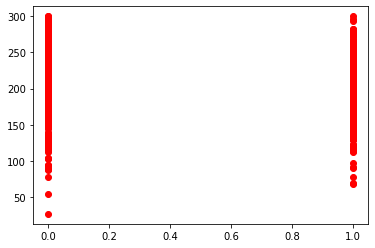

In [13]:
plt.scatter(df['enc_gender'], y, c='red')

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [15]:
model = LinearRegression()

In [16]:
X = df.values
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25)

In [17]:
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

In [18]:
from sklearn.metrics import mean_squared_error

In [19]:
error = np.sqrt(mean_squared_error(y_pred=y_pred, y_true=y_test))
error

2.5036928884157124e-14